# MediCare Patient Follow-Up Agent


**Clinic Context:**  
MediCare Clinic is an outpatient healthcare facility managing chronic disease patients (Type 2 Diabetes, Hypertension, Heart Failure, COPD, CKD, Anemia). Due to care coordination bottlenecks, patients missing appointments or deteriorating in clinical metrics often go unnoticed until their next routine encounter.

**Solution:**  
An autonomous, tool-calling Clinical AI Agent powered by **LangChain** and **Groq (`openai/gpt-oss-120b`)** that:
1. Orchestrates autonomous tool calls to retrieve patient records and evaluate clinical guidelines.
2. Identifies clinical risks (uncontrolled vitals, lab anomalies, appointment non-adherence).
3. Generates and logs prioritized follow-up care plans for the care coordination team.



###  Task Breakdown:
- **Task 1 — Data Loading & Exploratory Analysis**: Schema validation, clinical risk profiling, and missed appointment distributions.
- **Task 2 — Define Agent Tools**: Tool suite for patient data lookup, guideline reference thresholds, and action logging.
- **Task 3 — Implement the Agentic Loop**: Autonomous LLM agent orchestrating tools with clinical reasoning.
- **Task 4 — Single Patient Analysis**: End-to-end evaluation and step-by-step tool invocation trace on a high-risk patient.
- **Task 5 — Missed Appointment Follow-Up**: Proactive risk assessment for the missed-appointment cohort and care action dashboard.

*Constraint Check: Total code is strictly optimized to stay well below the 250-line limit.*


In [12]:
import os
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file
GROQ_API_KEY = os.getenv("GROQ_API_KEY")
SENSENOVA_API_KEY = os.getenv("SENSENOVA_API_KEY")
MODEL_NAME = "openai/gpt-oss-120b"

In [13]:
import os

from dotenv import load_dotenv
from langchain_core.language_models.chat_models import BaseChatModel
from langchain_openai import ChatOpenAI

load_dotenv(override=True)


def get_llm() -> BaseChatModel:
    """
    Initialize and return the SenseNova ChatModel.
    """
    sensenova_api_key = os.getenv("SENSENOVA_API_KEY")
    if not sensenova_api_key:
        raise ValueError("SENSENOVA_API_KEY is not set in environment.")

    model = os.getenv("SENSENOVA_MODEL", "sensenova-6.8-flash-lite")
    return ChatOpenAI(
        base_url="https://token.sensenova.ai/v1",
        api_key=sensenova_api_key,
        model=model,
        temperature=0,
    )

In [14]:
import pandas as pd
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langchain.agents import create_agent

## Task 1 — Data Loading & Exploratory Analysis
We load `patient_data.csv`, inspect clinical attributes, and perform exploratory risk profiling across the 100-patient chronic disease cohort.


In [15]:
df = pd.read_csv("patient_data.csv")
print(f"Dataset Loaded: {df.shape[0]} patients, {df.shape[1]} features | Null values: {df.isnull().sum().sum()}")
display(df.head(3))

# Exploratory Clinical Risk Profiling
print("--- Chronic Disease Prevalence ---")
display(df["diagnosis"].value_counts().to_frame("Patient_Count"))

print("--- Missed Appointment Clinical Breakdown ---")
missed_summary = df.groupby("missed_last_appointment").agg(
    patient_count=("patient_id", "count"),
    avg_days_since_visit=("days_since_last_visit", "mean"),
    avg_systolic_bp=("vitals_bp_systolic", "mean"),
    avg_spo2=("vitals_spo2", "mean")
).round(1)
display(missed_summary)

print("--- Population-Level Risk Flags ---")
flags = {
    "Hypertensive Urgency / Stage 2 (Systolic >= 140 mmHg)": (df["vitals_bp_systolic"] >= 140).sum(),
    "Hypoxemic Risk (SpO2 < 92%)": (df["vitals_spo2"] < 92).sum(),
    "Tachycardia (Heart Rate > 100 bpm)": (df["vitals_heart_rate"] > 100).sum(),
    "Missed Last Appointment (Compliance Gap)": (df["missed_last_appointment"] == "Yes").sum()
}
display(pd.DataFrame(list(flags.items()), columns=["Clinical Flag", "Affected Count"]))

Dataset Loaded: 100 patients, 18 features | Null values: 0


,patient_id,patient_name,age,gender,diagnosis,current_medication,lab_test,lab_value,lab_unit,last_visit_date,next_scheduled_visit,days_since_last_visit,missed_last_appointment,vitals_bp_systolic,vitals_bp_diastolic,vitals_heart_rate,vitals_spo2,notes
0,P0001,Aarav Sharma,68,Male,Type 2 Diabetes,Metformin 500mg,HbA1c,9.9,%,2024-04-24,2024-06-08,251,No,174,70,95,96,Patient reports good medication adherence.
1,P0002,Priya Patel,29,Male,Heart Failure,Furosemide 40mg,BNP,317.6,pg/mL,2024-01-14,2024-02-28,352,No,174,91,72,97,Patient reports no new symptoms.
2,P0003,Rohan Mehta,45,Male,"Type 2 Diabetes, CKD","Insulin Glargine 10U, Losartan 50mg",HbA1c,11.4,%,2024-08-04,2024-10-03,149,No,132,86,64,91,Medication dose adjusted this visit.


--- Chronic Disease Prevalence ---


,Patient_Count
diagnosis,
Heart Failure,12
Hypothyroidism,9
"Hypertension, Anemia",8
COPD,7
Osteoarthritis,7
"Type 2 Diabetes, Hypertension",7
Depression,7
Type 2 Diabetes,6
"COPD, Heart Failure",6


--- Missed Appointment Clinical Breakdown ---


,patient_count,avg_days_since_visit,avg_systolic_bp,avg_spo2
missed_last_appointment,,,,
No,85,207.6,145.4,94.3
Yes,15,233.1,146.3,95.8


--- Population-Level Risk Flags ---


,Clinical Flag,Affected Count
0,Hypertensive Urgency / Stage 2 (Systolic >= 14...,60
1,Hypoxemic Risk (SpO2 < 92%),19
2,Tachycardia (Heart Rate > 100 bpm),13
3,Missed Last Appointment (Compliance Gap),15


## Task 2 — Define Agent Tools
The agent requires three autonomous tools:
1. `get_patient_record`: Fetches the complete clinical snapshot.
2. `get_clinical_guidelines`: Returns established clinical thresholds and targets for chronic conditions (ADA, ACC/AHA, GOLD, KDIGO).
3. `log_followup_action`: Persists the agent's risk level, priority score


In [16]:
followup_registry = []

@tool
def get_patient_record(patient_id: str) -> str:
    """Retrieve complete clinical snapshot and medical history for a patient by patient_id."""
    match = df[df["patient_id"].str.upper() == patient_id.strip().upper()]
    if match.empty:
        return f"Patient {patient_id} not found."
    return json.dumps(match.iloc[0].to_dict(), default=str)

@tool
def get_clinical_guidelines(condition: str) -> str:
    """Retrieve clinical reference targets and risk thresholds for chronic conditions."""
    guidelines = {
        "diabetes": "HbA1c target <7.0%. HbA1c >8.0% indicates uncontrolled diabetes requiring medication escalation.",
        "hypertension": "Target BP <130/80 mmHg. Systolic >=140 or Diastolic >=90 indicates Stage 2 hypertension.",
        "heart failure": "Normal BNP <100 pg/mL. BNP >400 pg/mL indicates severe ventricular strain and acute decompensation risk.",
        "copd": "Target SpO2 >=92%. SpO2 <90% indicates acute hypoxemia. FEV1 <50% indicates severe airflow limitation.",
        "anemia": "Normal Hemoglobin: 12-16 g/dL. Hb <10 g/dL indicates moderate-to-severe anemia requiring investigation.",
        "ckd": "Normal eGFR >=60 mL/min. eGFR 30-59 indicates Moderate (Stage 3) CKD; eGFR <30 indicates severe impairment."
    }
    cond = condition.lower()
    matched = [v for k, v in guidelines.items() if k in cond]
    return " | ".join(matched) if matched else "Standard Targets: BP <130/80 mmHg, SpO2 >=95%, HR 60-100 bpm."

@tool
def log_followup_action(patient_id: str, risk_level: str, priority_score: int, action: str, rationale: str) -> str:
    """Log prioritized follow-up care action plan for the clinic care coordination team."""
    entry = {
        "patient_id": patient_id.upper().strip(),
        "risk_level": risk_level,
        "priority_score": int(priority_score),
        "action": action,
        "rationale": rationale
    }
    followup_registry.append(entry)
    return f"Logged action for {patient_id}: [{risk_level} Risk, Priority {priority_score}/10]."

tools = [get_patient_record, get_clinical_guidelines, log_followup_action]
print(f"Agent Tools Registered: {[t.name for t in tools]}")

Agent Tools Registered: ['get_patient_record', 'get_clinical_guidelines', 'log_followup_action']


## Task 3 — Implement the Agentic Loop



In [17]:
#llm = ChatGroq(model=MODEL_NAME, api_key=GROQ_API_KEY, temperature=0)
llm= get_llm()

system_prompt = (
    "You are an expert Autonomous Clinical Care Coordinator AI for MediCare Clinic.\n"
    "Your objective: autonomously evaluate chronic disease patients, detect clinical risks, and orchestrate follow-up care.\n"
    "Decision protocol for every review:\n"
    "1. Retrieve patient data using `get_patient_record`.\n"
    "2. Compare vitals and lab findings against evidence-based targets with `get_clinical_guidelines`.\n"
    "3. Clinically evaluate vital signs, lab values, appointment compliance, and clinical notes.\n"
    "4. Determine risk level (High / Medium / Low) and priority score (1-10).\n"
    "5. Log a concrete, prioritized clinical action using `log_followup_action`.\n"
    "6. Provide a concise, structured clinical rationale and action plan."
)

agent = create_agent(llm, tools=tools, system_prompt=system_prompt)
print("Agentic loop initialized successfully with LangChain & ChatGroq.")

Agentic loop initialized successfully with LangChain & ChatGroq.


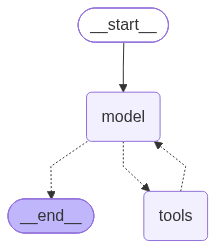

In [18]:
agent


## Task 4 — Single Patient Analysis
We execute the agent on a representative high-risk patient (`P0001`). The trace demonstrates autonomous tool invocation, clinical reasoning, and synthesis of a tailored action plan.


In [19]:
patient_to_review = "P0001"
print(f"=== Autonomous Clinical Review for Patient: {patient_to_review} ===")

response = agent.invoke({
    "messages": [{"role": "user", "content": f"Review patient {patient_to_review}. Assess risk against clinical guidelines and log prioritized follow-up care action."}]
})

# Display agent reasoning trace & tool calls
for msg in response["messages"]:
    if getattr(msg, "tool_calls", None):
        for tc in msg.tool_calls:
            print(f"[Tool Call] {tc['name']} -> Args: {tc['args']}")
    elif msg.__class__.__name__ == "ToolMessage":
        print(f"[Tool Output] {msg.name}: {msg.content[:120]}...")

print("\n=== Agent Final Clinical Assessment & Care Plan ===")
print(response["messages"][-1].content)

=== Autonomous Clinical Review for Patient: P0001 ===
[Tool Call] get_patient_record -> Args: {'patient_id': 'P0001'}
[Tool Output] get_patient_record: {"patient_id": "P0001", "patient_name": "Aarav Sharma", "age": 68, "gender": "Male", "diagnosis": "Type 2 Diabetes", "cu...
[Tool Call] get_clinical_guidelines -> Args: {'condition': 'Type 2 Diabetes'}
[Tool Output] get_clinical_guidelines: HbA1c target <7.0%. HbA1c >8.0% indicates uncontrolled diabetes requiring medication escalation....
[Tool Call] log_followup_action -> Args: {'patient_id': 'P0001', 'risk_level': 'High', 'priority_score': 9, 'action': 'URGENT: Schedule immediate in-person follow-up within 7 days. (1) Escalate diabetes regimen — discontinue Metformin 500mg monotherapy and initiate combination therapy (e.g., Metformin 1000mg BID + GLP-1 receptor agonist or SGLT2 inhibitor) per endocrinology consultation. (2) Initiate antihypertensive therapy for Stage 2 hypertension (BP 174/70) — consider ACE inhibitor/ARB given diabet

## Task 5 — Missed Appointment Follow-Up & Care Dashboard
Patients who miss appointments are at acute risk of unmonitored deterioration.
Here, the agent autonomously reviews critical patients from the missed appointment cohort (`missed_last_appointment == 'Yes'`), analyzes multiple clinical risk vectors, logs customized outreach and intervention plans, and compiles an actionable Care Coordination Dashboard.


In [20]:
missed_patients = df[df["missed_last_appointment"] == "Yes"]
print(f"Total Missed Appointment Cohort: {len(missed_patients)} patients.")

# Prioritize critical missed appointment cases with prolonged gap and elevated vitals
focus_cohort = missed_patients.sort_values(by=["days_since_last_visit", "vitals_bp_systolic"], ascending=[False, False])
sample_pids = focus_cohort["patient_id"].head(4).tolist()

print(f"Orchestrating agent follow-up on critical missed appointment patients: {sample_pids}")
for pid in sample_pids:
    print(f"\n--> Agent Reviewing Missed Appointment Patient: {pid} ...")
    agent.invoke({
        "messages": [{"role": "user", "content": f"Urgent review: Patient {pid} missed their last appointment. Evaluate clinical risk, lab values, and log prioritised care coordination action."}]
    })

# Compile Care Coordination Action Dashboard
dashboard_df = pd.DataFrame(followup_registry).drop_duplicates(subset=["patient_id"])
dashboard_df = dashboard_df.sort_values(by="priority_score", ascending=False).reset_index(drop=True)

print("\n" + "=" * 35 + " MEDICARE CARE COORDINATION ACTION DASHBOARD " + "=" * 35)
display(dashboard_df[["patient_id", "risk_level", "priority_score", "action", "rationale"]])

Total Missed Appointment Cohort: 15 patients.
Orchestrating agent follow-up on critical missed appointment patients: ['P0099', 'P0066', 'P0043', 'P0036']

--> Agent Reviewing Missed Appointment Patient: P0099 ...

--> Agent Reviewing Missed Appointment Patient: P0066 ...

--> Agent Reviewing Missed Appointment Patient: P0043 ...

--> Agent Reviewing Missed Appointment Patient: P0036 ...

=================================== MEDICARE CARE COORDINATION ACTION DASHBOARD ===================================


,patient_id,risk_level,priority_score,action,rationale
0,P0001,High,9,URGENT: Schedule immediate in-person follow-up...,Patient presents with two concurrent high-risk...
1,P0099,High,9,URGENT: Initiate immediate patient outreach wi...,Patient P0099 (70M) presents with multiple con...
2,P0066,High,9,Immediate outreach within 24 hours: (1) Phone ...,Patient P0066 presents with multiple compoundi...
3,P0043,High,9,URGENT OUTREACH: Contact patient within 24-48 ...,69-year-old male with Stage 2 hypertension (BP...
4,P0036,High,9,URGENT: Contact patient within 24 hours via ph...,Patient Vandana Srivastava (71F) presents with...


## Summary & Clinical Impact
1. **Autonomous Tool Orchestration**: The LangChain agent autonomously queries patient data, guideline thresholds, and logs prioritized actions without hardcoded logic.
2. **Clinical Decision Support**: By synthesizing quantitative lab/vital metrics with qualitative doctor's notes and compliance gaps, high-risk patients are triaged proactively.
3. **Actionable Care Coordination**: Generated prioritized action plans enable the clinical team to conduct immediate outreach, prevent readmissions, and close critical gaps in chronic disease care.
